# Abi Farraj et al.- WQT Markets - Fig. 2

In [7]:
file = 'Figures/'

# import data

import pandas as pd
import os
import numpy as np

# function that creates dataframe from list of files in a path
def create_dataframe_sensitivity(path, tag):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv'):
            # read the csv file
            df = pd.read_csv(path+file)

            # if file includes tag in name
            if tag in file:
                # create string with only the characters before "_summary.csv"
                mult = file.split('_summary.csv')[0]
                mult = mult.split(tag)[1]
                # save the dataframe in the dictionary
                try: 
                    mult = float(mult)
                    dfs[mult] = df
                except:
                    pass
                
    
    # sort the dictionary by key
    keys = {float(key):key for key in dfs.keys()}
    sorted_dfs = {}
    for key in sorted(keys.keys()):
        sorted_dfs[keys[key]] = dfs[keys[key]]
    return sorted_dfs

# function that creates dataframe from list of files in a path
def create_dataframe(path, tag):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv'):
            # read the csv file
            df = pd.read_csv(path+file)

            if tag == 'results':
                if 'results' not in file:
                    continue
                WWTP = file.split('results_')[1]
                WWTP = WWTP.split('.csv')[0]
                if 'econ' not in WWTP:
                    dfs[WWTP] = df
            
            # if file includes tag in name
            elif tag in file:
                # create string with only the characters after "results_econ_"
                WWTP= file.split('results_' + tag + '_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df
                
    return dfs
                    

def create_df(WWTP, dfs):
    df = dfs[WWTP]
    df.rename(columns={df.columns[0]: 'Datetime'}, inplace=True)
    df.Datetime = pd.to_datetime(df.Datetime)
    
    return df


def create_df_finance_econ(path, WWTPs):
    df_all_WWTPs = pd.DataFrame()
    for WWTP in WWTPs:
        path_finance = path + f'results_finance_{WWTP}.csv'
        path_econ = path + f'results_econ_{WWTP}.csv'
        df_finance = pd.read_csv(path_finance, index_col=0)
        df_finance = df_finance.reset_index().rename(columns={"index": "Year"})
        df_econ = pd.read_csv(path_econ, index_col=0)
        df_econ = df_econ.reset_index().rename(columns={"index": "Year"})
        
        # merge but only keep duplicate data from left
        df_w = pd.merge(df_econ, df_finance, on="Year", how="left", suffixes=('_NPV', '_finance'))
        df_w['WWTP'] = WWTP
        df_all_WWTPs = pd.concat([df_all_WWTPs, df_w], axis=0)

    return df_all_WWTPs

def change_dict_to_df(data_dict, column):
    df_credit = pd.DataFrame.from_dict(data_dict, orient='index', columns=column)
    df_credit = df_credit.reset_index()
    df_credit[['WWTP', 'Year']] = pd.DataFrame(df_credit['index'].tolist(), index=df_credit.index)
    df_credit = df_credit.drop(columns=['index'])
    # only show years from 10 to 30
    df_credit = df_credit[df_credit['Year'] >= 10]
    df_credit = df_credit[df_credit['Year'] <= 29]
    return df_credit

In [8]:
path_PA_SJSC = 'Results/Senstivity_bilat_trade_partners/Full_coordination/Palo Alto_SJSC/'
path_PA_Sunnyvale = 'Results/Senstivity_bilat_trade_partners/Full_coordination/Palo Alto_Sunnyvale/'
path_SJSC_Sunnyvale = 'Results/Senstivity_bilat_trade_partners/Full_coordination/SJSC_Sunnyvale/'
path_centralized_market = 'Results/Sensitivity_maxCredit_centralized_market_TR_1.0/Full_coordination_hotspot_0_yr_constrain_credits_bought/300/'
no_market = 'Results/Sensitivity_maxCredit_centralized_market_TR_1.0/No_coordination/'
path_CM_MaxLim = 'Results/Exchange_market_xmax_lim/Full_coordination_constrain_max_capacity_all/'

WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
Ls = ['SS', 'L2', 'L2upg3', 'L3']

df_PA_SJSC = create_df_finance_econ(path_PA_SJSC, WWTPs)
df_PA_Sunnyvale = create_df_finance_econ(path_PA_Sunnyvale, WWTPs)
df_SJSC_Sunnyvale = create_df_finance_econ(path_SJSC_Sunnyvale, WWTPs)
df_centralized_market = create_df_finance_econ(path_centralized_market, WWTPs)
df_CM_MaxLim = create_df_finance_econ(path_CM_MaxLim, WWTPs)
df_no_market = create_df_finance_econ(no_market, WWTPs)


years = df_PA_SJSC.index.unique()

In [9]:
def calculate_cost_savings(df_CM, df_NM, WWTPs):
    Ls = ['SS', 'L2', 'L3']
    Total_capex_CM = df_CM["Total_capex"].sum()
    Total_capex_NM = df_NM["Total_capex"].sum()
    Total_opex_CM = df_CM["Total_opex"].sum()
    Total_opex_NM = df_NM["Total_opex"].sum()
    print(f'Total CM capex: {round(Total_capex_CM, 2)}')
    print(f'Total NM capex: {round(Total_capex_NM, 2)}')
    cost_savings_capex = Total_capex_NM - Total_capex_CM
    cost_savings_opex = Total_opex_NM - Total_opex_CM
    cost_savings = cost_savings_capex + cost_savings_opex
    print(f'Total cost savings capex: {round(cost_savings_capex, 2)}')
    print(f'Total cost savings opex: {round(cost_savings_opex, 2)}')
    cost_savings_avoided = 0
    cost_savings_delayed = 0  
    for WWTP in WWTPs:
        df_CM_w = df_CM[df_CM.WWTP == WWTP]
        df_NM_w = df_NM[df_NM.WWTP == WWTP]
        for L in Ls:
            if df_CM_w['L2upg3_capex'].sum() > 0.01 or df_NM_w['L2upg3_capex'].sum() > 0.01:
                if L == 'L3':
                    Total_capex_CM_L = df_CM_w['L3_capex'].sum() + df_CM_w['L2_capex'].sum() + df_CM_w['L2upg3_capex'].sum()
                    Total_capex_NM_L = df_NM_w['L3_capex'].sum() + df_NM_w['L2_capex'].sum() + df_NM_w['L2upg3_capex'].sum()
                elif L == 'L2':
                    Total_capex_CM_L = 0
                    Total_capex_NM_L = 0
                else:
                    Total_capex_CM_L = df_CM_w[f"{L}_capex"].sum()
                    Total_capex_NM_L = df_NM_w[f"{L}_capex"].sum()
            else:
                Total_capex_CM_L = df_CM_w[f"{L}_capex"].sum()
                Total_capex_NM_L = df_NM_w[f"{L}_capex"].sum()

            if Total_capex_NM_L > 0 and Total_capex_CM_L == 0:
                cost_savings_L = Total_capex_NM_L - Total_capex_CM_L
                print(f'    Total cost savings avoided for {WWTP} {L}: {round(cost_savings_L, 2)}')
                cost_savings_avoided += cost_savings_L
            elif abs(Total_capex_CM_L - Total_capex_NM_L) > 0.01:
                cost_savings_L = Total_capex_NM_L - Total_capex_CM_L
                print(f'    Total cost savings delayed for {WWTP} {L}: {round(cost_savings_L, 2)}')
                cost_savings_delayed += cost_savings_L
    print(f'Total cost savings avoided: {round(cost_savings_avoided, 2)}, per of total cost savings: {round(cost_savings_avoided/cost_savings*100, 2)}%')
    print(f'Total cost savings delayed: {round(cost_savings_delayed, 2)}, per of total cost savings: {round(cost_savings_delayed/cost_savings*100, 2)}%')
    print(f'Total cost savings avoided + delayed: {round(cost_savings_avoided + cost_savings_delayed, 2)}')
    print(f'Total cost savings opex: {round(cost_savings_opex, 2)}, per of total cost savings: {round(cost_savings_opex/cost_savings*100, 2)}%')

    return cost_savings_avoided, cost_savings_delayed

calculate_cost_savings(df_centralized_market, df_no_market, WWTPs)

Total CM capex: 257.46
Total NM capex: 433.55
Total cost savings capex: 176.09
Total cost savings opex: 6.1
    Total cost savings delayed for Palo Alto L3: 8.64
    Total cost savings delayed for SJSC L2: 3.23
    Total cost savings avoided for Sunnyvale SS: 13.75
    Total cost savings avoided for Sunnyvale L2: 150.46
Total cost savings avoided: 164.22, per of total cost savings: 90.14%
Total cost savings delayed: 11.87, per of total cost savings: 6.52%
Total cost savings avoided + delayed: 176.09
Total cost savings opex: 6.1, per of total cost savings: 3.35%


(np.float64(164.2154213336058), np.float64(11.870586570583086))

 Lost cost savings in : 100 %
 Lost cost savings in Cost-optimal: 0 %
 Lost cost savings in WWTPs
not willing
to overbuild: 93 %
 Lost cost savings in Cost-optimal
(Palo Alto &
Sunnyvale): 10 %
 Lost cost savings in Palo Alto &
SJSC: 88 %


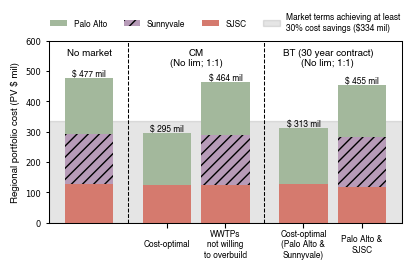

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}
Ls = ['SS', 'L2', 'L2upg3', 'L3']
custom_colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
hatches_WWTP = {'Sunnyvale': '///', 'SJSC': '', 'Palo Alto': ''}
fontsize_lab = 6
leg_size = 6
lab_size = 6
line_wid = 0.75
bord_wid = 2

y_base = 1
ciel = -(len(WWTPs)//-2)-1



fig, axs = plt.subplots(1, 1, figsize=(110/25.4, 72/25.4))  

total_cost_centralzed_market = {}
total_cost_PA_SJSC = {}
total_cost_PA_Sunnyvale = {}
total_cost_SJSC_Sunnyvale = {}
total_cost_no_market = {}
total_cost_CM_MaxLim = {}


#label_x = ['Centralized\nmarket','', '', '', 'No market']
#label_x_2 = ['WWTPs\nwilling\nto overbuild', 'WWTPs only\nsell excess\ncredits','Palo Alto &\nSunnyvale', 'SJSC &\nSunnyvale', 'Palo Alto &\nSJSC', '']
label_x_2 = ['', 'Cost-optimal', 'WWTPs\nnot willing\nto overbuild', 'Cost-optimal\n(Palo Alto &\nSunnyvale)', 'Palo Alto &\nSJSC']
#label_x_pos = [0.6, 1.2, 2.1, 2.7, 3.3, 4.2]
#label_x_pos = [0.6, 1.2, 2, 2.6, 3.2, 4]
label_x_pos = [1, 1.8, 2.4, 3.2, 3.8]

bottom_centralized_market = 0
bottom_CM_MaxLim = 0
bottom_PA_SJSC = 0
bottom_PA_Sunnyvale = 0
bottom_SJSC_Sunnyvale = 0
bottom_centralized_market = 0
bottom_no_market = 0



for WWTP in WWTPs:

    df_PA_SJSC_year = df_PA_SJSC[df_PA_SJSC['WWTP'] == WWTP]
    df_PA_Sunnyvale_year = df_PA_Sunnyvale[df_PA_Sunnyvale['WWTP'] == WWTP]
    df_SJSC_Sunnyvale_year = df_SJSC_Sunnyvale[df_SJSC_Sunnyvale['WWTP'] == WWTP]
    df_centralized_market_year = df_centralized_market[df_centralized_market['WWTP'] == WWTP]
    df_no_market_year = df_no_market[df_no_market['WWTP'] == WWTP]
    df_CM_MaxLim_year = df_CM_MaxLim[df_CM_MaxLim['WWTP'] == WWTP]

    total_cost_PA_SJSC[WWTP] = df_PA_SJSC_year['Total_capex'].sum() + df_PA_SJSC_year['Total_opex'].sum()
    total_cost_PA_Sunnyvale[WWTP] = df_PA_Sunnyvale_year['Total_capex'].sum() + df_PA_Sunnyvale_year['Total_opex'].sum()
    total_cost_SJSC_Sunnyvale[WWTP] = df_SJSC_Sunnyvale_year['Total_capex'].sum() + df_SJSC_Sunnyvale_year['Total_opex'].sum()
    total_cost_centralzed_market[WWTP] = df_centralized_market_year['Total_capex'].sum() + df_centralized_market_year['Total_opex'].sum()
    total_cost_no_market[WWTP] = df_no_market_year['Total_capex'].sum() + df_no_market_year['Total_opex'].sum()
    total_cost_CM_MaxLim[WWTP] = df_CM_MaxLim_year['Total_capex'].sum() + df_CM_MaxLim_year['Total_opex'].sum()

    axs.bar(
        label_x_pos,
        #[total_cost_centralzed_market[WWTP],total_cost_CM_MaxLim[WWTP], total_cost_PA_Sunnyvale[WWTP], total_cost_SJSC_Sunnyvale[WWTP], total_cost_PA_SJSC[WWTP], total_cost_no_market[WWTP]],
        [total_cost_no_market[WWTP], total_cost_centralzed_market[WWTP], total_cost_CM_MaxLim[WWTP], total_cost_PA_Sunnyvale[WWTP], total_cost_PA_SJSC[WWTP]],
        color=colors_WWTP[WWTP],
        hatch=hatches_WWTP[WWTP],
        label=WWTP,
        width=0.5,
        #bottom=[bottom_centralized_market, bottom_CM_MaxLim, bottom_PA_Sunnyvale, bottom_SJSC_Sunnyvale, bottom_PA_SJSC, bottom_no_market],
        bottom = [bottom_no_market, bottom_centralized_market, bottom_CM_MaxLim, bottom_PA_Sunnyvale, bottom_PA_SJSC]
    )

    # Update cumulative bottoms
    bottom_PA_SJSC += total_cost_PA_SJSC[WWTP]
    bottom_PA_Sunnyvale += total_cost_PA_Sunnyvale[WWTP]
    bottom_SJSC_Sunnyvale += total_cost_SJSC_Sunnyvale[WWTP]
    bottom_centralized_market += total_cost_centralzed_market[WWTP]
    bottom_CM_MaxLim += total_cost_CM_MaxLim[WWTP]
    bottom_no_market += total_cost_no_market[WWTP]

#bottoms = [bottom_centralized_market, bottom_CM_MaxLim, bottom_PA_Sunnyvale, bottom_SJSC_Sunnyvale, bottom_PA_SJSC, bottom_no_market]
bottoms = [bottom_no_market, bottom_centralized_market, bottom_CM_MaxLim, bottom_PA_Sunnyvale, bottom_PA_SJSC]

ideal_cost_savings = bottom_no_market - bottom_centralized_market

for i,cost in enumerate(bottoms):
    axs.text(label_x_pos[i],cost + 15,
                    f'$ {cost:,.0f} mil', ha='center', va='center', color='black', fontweight='bold', fontsize=fontsize_lab, fontname='Helvetica')
    print(f' Lost cost savings in {label_x_2[i]}: {((cost - bottom_centralized_market)/ ideal_cost_savings)*100:,.0f} %')

#markets = ['CM\n(No lim; 1:1)', 'BT (30 year contract)\n(No lim; 1:1)', 'No market']
markets = ['No market','CM\n(No lim; 1:1)', 'BT (30 year contract)\n(No lim; 1:1)']

#x_border = [label_x_pos[1]+ (label_x_pos[2]-label_x_pos[1])/2, label_x_pos[4]+ (label_x_pos[5]-label_x_pos[4])/2]
x_border = [label_x_pos[0]+ (label_x_pos[1]-label_x_pos[0])/2, label_x_pos[2]+ (label_x_pos[3]-label_x_pos[2])/2, label_x_pos[4]+ (label_x_pos[4]-label_x_pos[3])/2]

for i , txt in enumerate(markets):
    if i == 0:
        lab_x = label_x_pos[0]
    elif i == 1:
        lab_x = (x_border[1] - x_border[0])/2 + x_border[0]
    else:
        lab_x = (x_border[2] - x_border[1])/2 + x_border[1]

    axs.text(lab_x, 575, txt, ha='center', va='top', color='black', fontweight='bold', fontsize=fontsize_lab + 1, fontname='Helvetica')

"""
for i, txt in enumerate(label_x_2):
    axs.text(label_x_pos[1 + i], -45,
                    txt, ha='center', va='center', color='black', fontweight='normal', fontsize=fontsize_lab, fontname='Helvetica')
"""

#add horizontal line at 30% cost savings relative to no market behind the bars
#axs.axhline(y = bottom_no_market *0.7, color='black', linestyle='--', linewidth=0.5, zorder=0, alpha=0.5)
#add shaded region behind the bars for 30% cost savings relative to no market
axs.axhspan(0, bottom_no_market *0.7, color='black', alpha=0.1, zorder=0, label= 'Market terms achieving at least\n30% cost savings ($334 mil)', linewidth=1)

#add legend in opposite order of bars
labels = axs.get_legend_handles_labels()[1]
handles = axs.get_legend_handles_labels()[0]
axs.legend(reversed(handles), reversed(labels), loc='center', prop={'family':'Helvetica', 'size':lab_size}, frameon=False, bbox_to_anchor=(0.5, 1.1), ncol=4)

#axs.legend(loc='center', prop={'family':'Helvetica', 'size':lab_size}, frameon=False, bbox_to_anchor=(0.5, 1.05), ncol=3)
axs.axvline(x = x_border[0], color='black', linestyle='--', linewidth=line_wid)
axs.axvline(x = x_border[1], color='black', linestyle='--', linewidth=line_wid)


axs.set_ylabel('Regional portfolio cost (PV $ mil)', **hfont)
axs.set_xticks(label_x_pos[1:6])

axs.set_xticklabels(labels=label_x_2[1:6], rotation=0, **hfont_ticks, va='center')
axs.tick_params(axis='x', pad=12)

axs.set_ylim(0, 600)
axs.xaxis.set_ticks_position('bottom')
axs.tick_params(axis="y", width=line_wid, length=bord_wid, labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

plt.tight_layout()
plt.savefig(file + '/Fig2c.svg', format='svg', dpi=300)


In [11]:
path = 'Results/Senstivity_bilat_contract_yr/'

dfs_bilat = create_dataframe_sensitivity(path, 'Full_coordination_')


Cost savings with 30.0 year bilateral contract: 34.5 % compared to no market, and 312.6 total cost
Cost savings with 15.0 year bilateral contract: 34.5 % compared to no market, and 312.6 total cost
Cost savings with 10.0 year bilateral contract: 34.5 % compared to no market, and 312.4 total cost
Cost savings with 5.0 year bilateral contract: 34.9 % compared to no market, and 310.4 total cost
Cost savings with 1.0 year bilateral contract: 36.4 % compared to no market, and 303.4 total cost


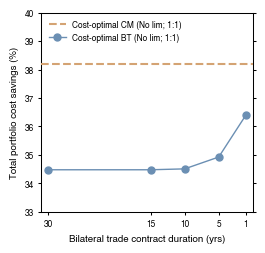

In [12]:
markers = ['o', 'd', 's']
labels = ['SS', 'L2', 'L2upg3', 'L3']
colors = ['green', 'red', 'purple', 'black', 'yellow', 'pink', 'brown', 'grey']
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
fontsize_lab = 6
leg_size = 6
lab_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 5
line_fig_wid = 1

fig, axs = plt.subplots(1, 1, figsize=(70/25.4, 67/25.4))


# Plot total costs for SNC
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
dfs = dfs_bilat

x_max = 30
x_min = 0
keys_reversed = [key for key in reversed(dfs.keys()) if key != 2]
keys = {float(key):key for key in keys_reversed}
ticks = [float(key) for key in keys_reversed]
xticks = np.arange(0, 31, 5)


total_opex = [dfs[key]['Total_opex'][3] for key in keys_reversed]
total_cost = [dfs[key]['Total_cost'][3] for key in keys_reversed]
total_capex = [dfs[key]['Total_capex'][3] for key in keys_reversed]
lost_savings = (total_cost - bottom_centralized_market)/ideal_cost_savings * 100
total_savings = (bottom_no_market-total_cost)/bottom_no_market * 100
CM_total_savings = (bottom_no_market-bottom_centralized_market)/bottom_no_market * 100
available_savings = 100 - lost_savings

for i, txt in enumerate(keys_reversed[:-1]):
    print(f'Cost savings with {txt} year bilateral contract: {total_savings[i]:.1f} % compared to no market, and {total_cost[i]:.1f} total cost')

for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
    spine.set_zorder(0)

#line_2 = axs.plot(1, CM_total_savings, label='Cost-optimal CM (No lim; 1:1)', marker='o', color='#D4A373', linestyle='', linewidth=line_fig_wid, markersize=m_size, zorder=3)
line_2 = axs.axhline(CM_total_savings, color='#D4A373', linestyle='--', linewidth=1.5, zorder=3, label='Cost-optimal CM (No lim; 1:1)')
line = axs.plot(ticks[:-1], total_savings[:-1], label='Cost-optimal BT (No lim; 1:1)', marker='o', color='#6B8FB3', linestyle='-', linewidth=line_fig_wid, markersize=m_size, zorder=3)

#axs.axvline(x = 10, color='black', linestyle='--', linewidth=line_fig_wid)
#axs.axhline(y=total_cost[0], label='Centralized market', color='#D4A373', linestyle='--', linewidth=line_fig_wid)
line[0].set_clip_on(False)
#line_2[0].set_clip_on(False)
# show the data points over the border lines


# invert x-axis
axs.invert_xaxis()
xticks = [int(keys_reversed[i]) for i in range(len(keys_reversed[:-1]))]

axs.set_xticks(xticks, xticks, **hfont_ticks)

axs.set_xlim([0, 31])
axs.invert_xaxis()
axs.set_ylim([33, 40])
axs.set_yticks(np.arange(33, 41, 1), np.arange(33, 41, 1), **hfont_ticks)

# Split your handles and labels
lab, leg = axs.get_legend_handles_labels()
# First legend - upper left (first item only)
axs.legend(loc='upper left', prop={'family': 'Helvetica', 'size': leg_size}, frameon=False)
#leg1 = axs.legend([lab[1]], [leg[1]], loc='upper left', prop={'family': 'Helvetica', 'size': leg_size}, frameon=False)
# Add it manually so it doesn't get replaced
#axs.add_artist(leg1)
# Second legend - lower left (second item only)
#leg2 = axs.legend([lab[0]], [leg[0]], loc='lower left', prop={'family': 'Helvetica', 'size': leg_size}, frameon=False)
    

#axs.set_ylabel('Available cost savings compared to\n centralized market(%)', **hfont)
axs.set_ylabel('Total portfolio cost savings (%)', **hfont)
axs.set_xlabel('Bilateral trade contract duration (yrs)', **hfont)

#add ytickmarks also on the right
axs.yaxis.set_ticks_position('both')
axs.xaxis.set_ticks_position('bottom')
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=lab_size)

    
plt.tight_layout()
plt.savefig(file + '/Fig2b.svg', format='svg', dpi=300)
    

In [13]:
path_bilat = 'Results/Sensitivity_maxCredit_bilat_contract_30yrs_TR_'
path_centralized = 'Results/Sensitivity_maxCredit_centralized_market_TR_'


TRs = [1.0, 1.5, 2.0, 2.5]
dfs_bilat_30yrs = {}
dfs_centralized = {}
dfs_NC = {}

for TR in TRs:
    path_bilat_TR = path_bilat + f'{TR}/'
    path_centralized_TR = path_centralized + f'{TR}/'
    path_NC = path_centralized_TR + f'No_coordination_summary.csv'
    dfs_bilat_30yrs[TR] = create_dataframe_sensitivity(path_bilat_TR, 'Full_coordination_hotspot_0_yr_constrain_credits_bought_')
    dfs_centralized[TR] = create_dataframe_sensitivity(path_centralized_TR, f'Full_coordination_hotspot_0_yr_constrain_credits_bought_')
    #dfs_centralized[TR] = create_dataframe_sensitivity(path_centralized_TR, f'Full_coordination_hotspot_0_yr_')
    #dfs_bilat_30yrs[TR] = create_dataframe_sensitivity(path_centralized_TR, f'Full_coordination_hotspot_0_yr_')
    dfs_NC[TR] = pd.read_csv(path_NC)


Base cost: 294.8319376065268 CoC during market: 270.7718330086562
Cost no market: 477.01710496877934 CoC no market: 344.0099952072206
Ideal savings: 182.1851673622525
Max portfolio costs to achieve 30% savings: 333.91
CoC saved with market: 73.24 ( 21.29 %)
Centralized Market:
    (2.5,No limit): 316
    (2.5,50): 316
    (2.5,25): 316
    (2.5,10): 320
    (2.0,No limit): 315
    (2.0,50): 315
    (2.0,25): 315
    (2.0,10): 320
    (1.5,No limit): 311
    (1.5,50): 311
    (1.5,25): 313
    (1.5,10): 318
    (1.0,No limit): 295
    (1.0,50): 302
    (1.0,25): 311
    (1.0,10): 316
Bilateral trades (30 year contract):
    (2.5,No limit): 324
    (2.5,50): 324
    (2.5,25): 324
    (2.5,10): 325
    (2.0,No limit): 324
    (2.0,50): 324
    (2.0,25): 324
    (2.0,10): 325
    (1.5,No limit): 323
    (1.5,50): 323
    (1.5,25): 324
    (1.5,10): 325
    (1.0,No limit): 313
    (1.0,50): 313
    (1.0,25): 323
    (1.0,10): 325


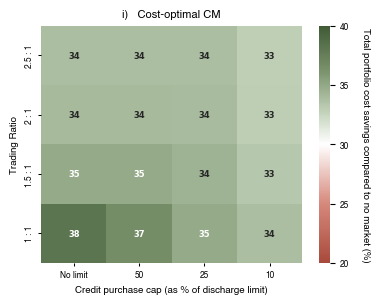

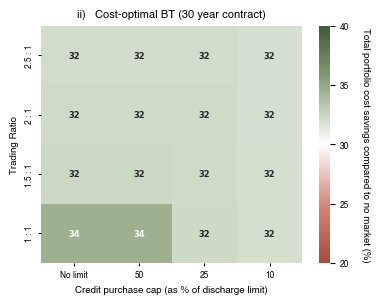

In [14]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.colors as mcolors

num_colors = False
center_val=30
vmin_val=20
vmax_val=40

if num_colors == 4:
    list = [0, 30, 35, 40]
    cmap_val = sns.color_palette(["#7A2E0E", "#B4533C", "#D17A5B", "#E6B8A2"], as_cmap=True)
    #shades of green in reverse
    cmap_val = sns.color_palette(["#E5F5F9", "#66C2A4", "#238B45", "#00441B"], as_cmap=True)

elif num_colors == 5:
    list = [20,25, 30, 35, 40]
    cmap_val = sns.color_palette(["#7A2E0E", "#B4533C", "#D17A5B", "#E6B8A2", "#F2E9E4"], as_cmap=True)
    cmap_val = sns.color_palette(["#EAF3E5", "#B9DCA6", "#7FBE66", "#4D9A3C", "#235E1C"], as_cmap=True)
else:
    list = [20, 25, 30, 35, 40]
    cmap_val = mcolors.LinearSegmentedColormap.from_list(
    "red_white_green",
    [
        (0.00, "#A84A3C"),   # value 20 -> deep dusty rose
        (0.25, "#D6897C"),   # value 25 -> rose
        (0.50, "#FFFFFF"),   # value 30 -> white
        (0.65, "#BCCDB3"),   # value 33 -> pale sage
        (0.80, "#7E9670"),   # value 36 -> sage
        (1.00, "#3F5A35"),   # value 40 -> deep green
    ],
    N=256,                    # 256 levels -> continuous, no banding
    )

TRs = dfs_bilat_30yrs.keys()
hotspots= dfs_bilat_30yrs[1.0].keys()

TR_keys = [float(key) for key in TRs]
hotspot_keys = [float(key) for key in hotspots]

#key_tag = {1.0: r'$1\boldsymbol{:}1$', 1.5: r'$1.5\boldsymbol{:}1$', 2.0: r'$2\boldsymbol{:}1$', 2.5: r'$2.5\boldsymbol{:}1$'}
#key_tag = {1.0: '1:1', 1.5: '1.5:1', 2.0: '2:1', 2.5: '2.5:1'}
key_tag = {1.0: '1 : 1', 1.5: '1.5 : 1', 2.0: '2 : 1', 2.5: '2.5 : 1'}
TR_key_tag = [key_tag[key] for key in TRs]

hfont_titles = {'fontname':'Helvetica', 'size':8, 'fontweight': 'bold'}
#hotspot_xtag = 'Max credits purchased (as % of discharge limit)'
hotspot_xtag = 'Credit purchase cap (as % of discharge limit)'
TR_xtag = 'Trading Ratio'



df = pd.DataFrame()

base_cost = dfs_centralized[1.0][300]['Total_cost'][3]
cost_no_market = dfs_NC[1.0]['Total_cost'][3]
CoC_during_market = dfs_centralized[1.0][300]['Total_CoC_during_market'][3]
CoC_no_market = dfs_NC[1.0]['Total_CoC_during_market'][3]

print('Base cost:', base_cost, 'CoC during market:', CoC_during_market)
print('Cost no market:', cost_no_market, 'CoC no market:', CoC_no_market)
ideal_savings =  cost_no_market - base_cost
print('Ideal savings:', ideal_savings)
print('Max portfolio costs to achieve 30% savings:', round(cost_no_market*0.7,2))
print('CoC saved with market:', round(CoC_no_market - CoC_during_market,2), '(',  round((CoC_no_market - CoC_during_market)/CoC_no_market * 100,2), '%)')

print('Centralized Market:')
for TR in TR_keys[::-1]:
    for mult in hotspot_keys[::-1]:
        mult_2 = str(int(float(mult)*100))
        if mult > 10:
            mult_2 = 'No limit'
        new_cost = dfs_centralized[TR][mult]['Total_cost'][3]
        lost_savings = (new_cost - base_cost)/ideal_savings * 100
        available_savings = 100 - lost_savings 
        total_savings = (cost_no_market - new_cost)/cost_no_market * 100
        #df.loc[TR, mult_2] = lost_savings
        #df.loc[TR, mult_2] = available_savings
        #df.loc[TR, mult_2] = total_savings
        df.loc[key_tag[TR], mult_2] = total_savings
        print(f'    ({TR},{mult_2}): {round(new_cost)}')
        fmt_tag = ".0f"
        


fig, axs = plt.subplots(1, 1, figsize=(100/25.4, 80/25.4))
sns.heatmap(df, annot=True, fmt=fmt_tag, cmap=cmap_val, vmin=vmin_val, vmax=vmax_val, cbar_kws={"ticks": list}, annot_kws={"fontsize": leg_size, "fontweight": "bold"})
#sns.heatmap(df, annot=True, fmt=fmt_tag)
#cmap_val = plt.cm.RdGy(np.linspace(0.25, 1, 256))
cbar = axs.collections[0].colorbar
cbar.ax.set_ylabel('Total portfolio cost savings compared to no market (%)', rotation=270, labelpad=15, **hfont)
cbar.ax.set_yticklabels(cbar.ax.get_yticklabels(), **hfont_ticks)
#cbar.ax.set_yticklabels(TR_key_tag, **hfont_ticks)

# change cmap scale from 250 to 350

axs.tick_params(axis="both", which='major', labelfontfamily= 'Helvetica', width=line_wid, length=bord_wid, labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

axs.set_ylabel(TR_xtag, **hfont)
axs.set_xlabel(hotspot_xtag, **hfont)
plt.title('i)   Cost-optimal CM', **hfont_titles)
plt.tight_layout()
plt.savefig(file + '/Fig2ai.svg', format='svg', dpi=300)


print('Bilateral trades (30 year contract):')
for TR in TR_keys[::-1]:
    for mult in hotspot_keys[::-1]:
        mult_2 = str(int(float(mult)*100))
        if mult > 10:
            mult_2 = 'No limit'
        new_cost = dfs_bilat_30yrs[TR][mult]['Total_cost'][3]
        lost_savings = (new_cost - base_cost)/ideal_savings * 100
        available_savings = 100 - lost_savings
        print(f'    ({TR},{mult_2}): {round(new_cost)}')
        total_savings = (cost_no_market - new_cost)/cost_no_market * 100
        #df.loc[TR, mult_2] = lost_savings
        #df.loc[TR, mult_2] = available_savings
        df.loc[key_tag[TR], mult_2] = total_savings
        fmt_tag = ".0f"
        


fig, axs = plt.subplots(1, 1, figsize=(100/25.4, 80/25.4))
#sns.heatmap(df, annot=True, fmt=fmt_tag, cmap=cmap_val, center=center_val, vmin=vmin_val, vmax=vmax_val, cbar_kws={"ticks": np.arange(0, 21, 4)}, annot_kws={"fontsize": leg_size, "fontweight": "bold"})
sns.heatmap(df, annot=True, fmt=fmt_tag, cmap=cmap_val, vmin=vmin_val, vmax=vmax_val, cbar_kws={"ticks": list}, annot_kws={"fontsize": leg_size, "fontweight": "bold"})
cbar = axs.collections[0].colorbar
cbar.ax.set_ylabel('Total portfolio cost savings compared to no market (%)', rotation=270, labelpad=15, **hfont)
cbar.ax.set_yticklabels(cbar.ax.get_yticklabels(), **hfont_ticks)



# change cmap scale from 250 to 350

axs.tick_params(axis="both", which='major', labelfontfamily= 'Helvetica', width=line_wid, length=bord_wid, labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

axs.set_ylabel(TR_xtag, **hfont)
axs.set_xlabel(hotspot_xtag, **hfont)
plt.title('ii)   Cost-optimal BT (30 year contract)', **hfont_titles)
plt.tight_layout()
plt.savefig(file + '/Fig2aii.svg', format='svg', dpi=300)
